# Clean speech (single speaker)

Part of the per-condition split of `cortical_analysis.ipynb`; runs on its own.
Shared settings (models, fit parameters, ROI, peak windows, plot window) are in
`parameters.py`.

**Results come from the cluster.** Every fit and model test is computed and kept on the
cluster; this notebook only reads them and saves nothing. In the cluster's JupyterHub
(any browser, laptop closed) it reads them from the cluster's disk; on the Mac (VS Code or
Jupyter), open the connection once in a terminal with `bash cluster/connect.sh`. The
`check_results` cell below asks the cluster for anything missing by itself, waits for the job
and then carries on, so one Run All goes from start to finish (keep the computer awake). See `cluster/README.md`.

**Peaks:** each subject's peak is searched within +-25 ms of where that condition's
group-average waveform peaks inside the search window (`add_anchored_peak`).

**Per-bin TRF plots** (`plot_trf_bins`): one line per frequency bin in its own colour
with a band of +-1 SEM across subjects (`BIN_ERROR` in `parameters.py`), the mean of
the bins as the thick black line, and the bins' centre frequencies on the right.

In [1]:
from parameters import *

In [2]:
# Checks that every result this notebook reads is on the cluster. If any are missing it
# asks the cluster for them, waits for the job (a line whenever its state changes) and
# carries on. Keep the computer awake while it waits.
check_results('clean')

3 of 3 results this notebook reads are not on the cluster yet; asking the cluster for them.
Submitted job 9230808 for clean. Follow it with cluster_queue(); the cluster also emails when it ends.
Waiting for job 9230808 (checked every minute; the cluster also emails when it ends). Interrupting only stops the waiting, not the job.
  20:29  9230808 running  (0 min so far)
Job 9230808 is done: all 3 results are on the cluster. Carrying on with the notebook.


In [3]:
# Your cluster jobs (PD = waiting for a slot, R = running).
cluster_queue()

          JOBID     USER      ACCOUNT           NAME  ST  TIME_LEFT NODES CPUS TRES_PER_N MIN_MEM NODELIST (REASON) 
        9230740     iggy def-ibruce_c cocktail-dioti   R 1-23:44:05     1   32        N/A    128G nc10341 (None) 



In [4]:
# The end of the latest cluster job's log (or cluster_log(<job number>)).
cluster_log()

== cocktail-clean-9230808.out
INFO    :  *** BinauralCocktail initialized with root /lustre06/project/6005583/iggy/dataset/cocktail/bids on 2026-11-12 20:30:10 ***
INFO    :  Using eelbrain 0.0.0, mne 1.13.2.
INFO    :  *** BinauralCocktail initialized with root /lustre06/project/6005583/iggy/dataset/cocktail/bids on 2026-11-12 20:30:47 ***
INFO    :  Using eelbrain 0.0.0, mne 1.13.2.
  bad-channels file already exists for: 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12, 13. Skip all of them (default) or redo and overwrite all of them? [s/r]: s  (COCKTAIL_ANSWER)
  skipping (already done): 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12, 13

Done. Bad channels marked.
  ICA file already exists for: 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12, 13. Skip all of them (default) or redo and overwrite all of them? [s/r]: s  (COCKTAIL_ANSWER)
  skipping (already done): 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12, 13

Done. ICA fit and artifact components selected.
=== clean  2026-11-12 20

## Clean speech (single speaker)

In [5]:
# Loaded once here, reused by every STRF/peak/waveform cell below in
# this section - each one just reads a different predictor column out
# of this same fit instead of re-running the (expensive) TRF fit again.
data_full = load_trfs_saved(FULL_CLEAN, 'clean')

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


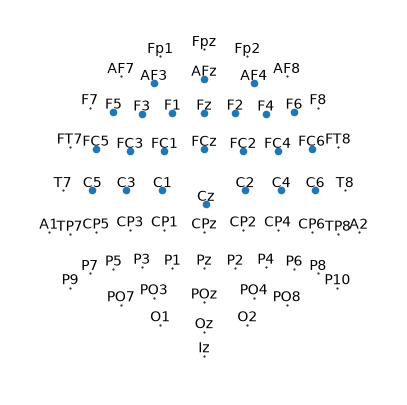

In [6]:
# ROI sensors
p = plot.SensorMap(data_full['gammatone_8'].sensor, mark=ROI)

<small>

**Brodbeck et al. 2020: Clean, onset unique contribution**

- Onsets add their own predictive power: t_max = 12.00, p ≤ 0.001
- Found in auditory cortex on both sides (Heschl's gyrus and superior temporal gyrus)
- Almost every subject shows a gain
- Best overall model fit: r = 0.143

</small>

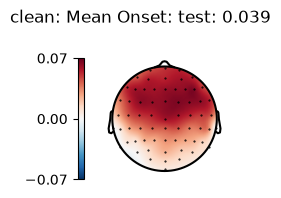

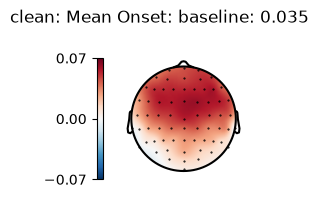

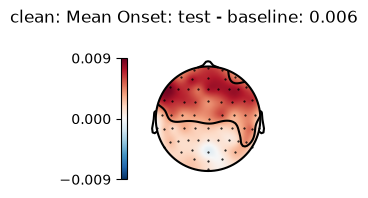

In [7]:
# Onset unique contribution (clean)
# Brodbeck et al. 2020 ran this comparison too: single-speaker onset unique contribution, t = 12.00, p <= .001.
data, diff, result = compute_unique_contribution(FULL_CLEAN, onset(ATTEND), 'clean')
show_topomap_trio(data, diff, result, 'Onset', 'clean', onset(ATTEND))

In [8]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Onset (clean): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, pmin=0.05, 2 clusters, p = .002>

Onset (clean): ROI unique contribution t(12) = 2.755, p = 0.0087


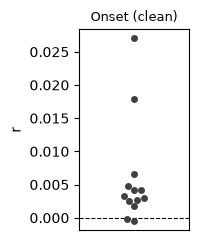

In [9]:
p = show_subject_swarm(diff, 'Onset', 'clean')

<small>

**Brodbeck et al. 2020: Clean, envelope unique contribution**

- Envelope adds its own predictive power: t_max = 9.39, p ≤ 0.001
- Same place: auditory cortex on both sides
- Almost every subject shows a gain

</small>

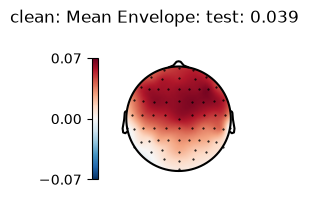

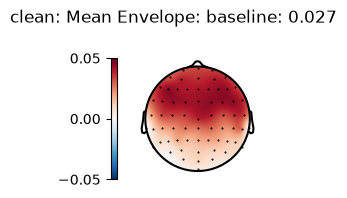

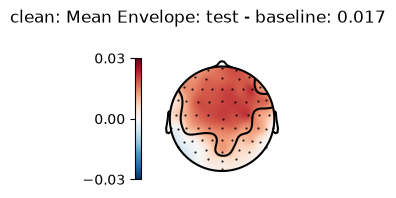

In [10]:
# Envelope unique contribution (clean)
# Brodbeck et al. 2020 ran this comparison too: single-speaker envelope unique contribution, t = 9.39, p <= .001.
data, diff, result = compute_unique_contribution(FULL_CLEAN, envelope(ATTEND), 'clean')
show_topomap_trio(data, diff, result, 'Envelope', 'clean', envelope(ATTEND))

In [11]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Envelope (clean): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, pmin=0.05, 1 clusters, p = .009>

Envelope (clean): ROI unique contribution t(12) = 2.709, p = 0.0095


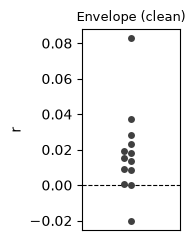

In [12]:
p = show_subject_swarm(diff, 'Envelope', 'clean')

<small>

**Brodbeck et al. 2020: Clean, onset STRF**

- Clear two-peak shape: a positive peak, then a negative peak
- Same shape in every frequency band
- Bigger at lower frequencies

</small>

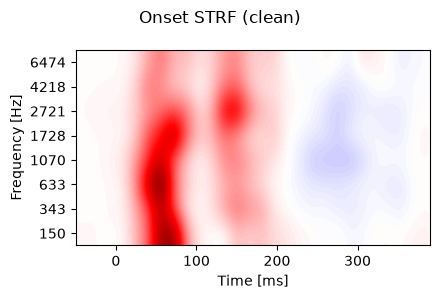

In [13]:
# Onset STRF (clean)
strf = extract_strf(data_full, 'gammatone_on_8')
p = plot.Array(strf * 1e3, title='Onset STRF (clean)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

<small>

**Brodbeck et al. 2020: Clean, envelope STRF**

- Weaker and less clear-cut than the onset STRF (onsets explain much of what usually looks like an envelope response)
- Fitted without onsets, the envelope STRF shows the usual clear peaks, with bigger amplitude
- Bigger at lower frequencies
- Shown from -50 to 450 ms "because of occasional edge artifacts" (fit window -100 to 500 ms)

</small>

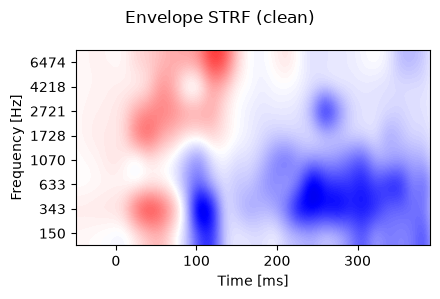

In [14]:
# Envelope STRF (clean)
strf = extract_strf(data_full, 'gammatone_8')
p = plot.Array(strf * 1e3, title='Envelope STRF (clean)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

<small>

**Brodbeck et al. 2020: Clean, onset peaks**

- Positive peak: 65 ms (average over subjects)
- Negative peak: 126 ms
- Peak search window: 20 to 200 ms (this notebook: 40 to 200 ms)

</small>

In [15]:
# Onset peak amplitude & timing (clean)
# Brodbeck et al. 2020 ran this comparison too: onset STRF positive peak ~65ms, negative peak ~126ms.
data = extract_trf(data_full, 'gammatone_on_8')
data = add_anchored_peak(data, 'positive', ONSET_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ONSET_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Onset (clean) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Onset (clean) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Onset (clean) positive peak: 55 ms, amp 0.008226
Onset (clean) negative peak: 108 ms, amp 0.0001225


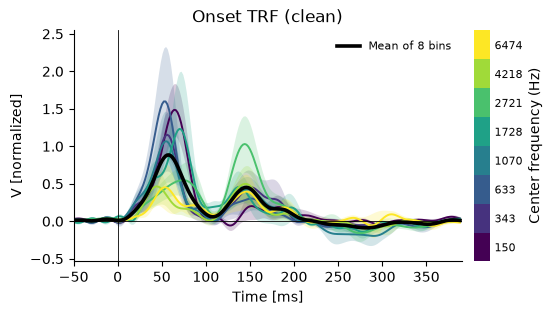

In [16]:
# The TRF the peaks above were measured from, per frequency bin
p = plot_trf_bins(data_full, 'gammatone_on_8', 'Onset TRF (clean)')

<small>

**Brodbeck et al. 2020: Clean, envelope peaks**

- No envelope peak latencies reported (the envelope STRF has no clear peaks)

</small>

In [17]:
# Envelope peak amplitude & timing (clean)
data = extract_trf(data_full, 'gammatone_8')
data = add_anchored_peak(data, 'positive', ENVELOPE_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ENVELOPE_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Envelope (clean) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Envelope (clean) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Envelope (clean) positive peak: 51 ms, amp 0.002896
Envelope (clean) negative peak: 103 ms, amp -0.00259


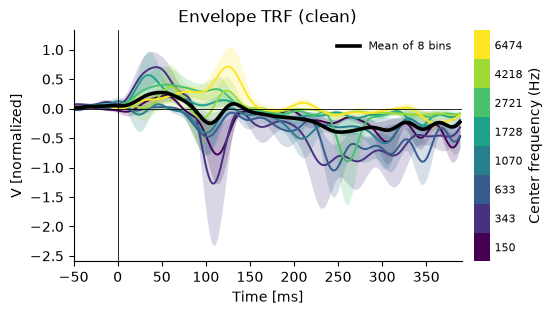

In [18]:
# The TRF the peaks above were measured from, per frequency bin
p = plot_trf_bins(data_full, 'gammatone_8', 'Envelope TRF (clean)')